In [2]:
%%time
import h5py
import pickle
import matplotlib.pyplot as plt

pickle_in = open("/home/lwu/ARCHS4/Tests/5M Threshold Sample Retention Plots/5M_threshold_sample_idxs_list.pkl", 'rb')
threshold_sample_idxs = pickle.load(pickle_in)
pickle_in.close()

# ---------------------------------------------------------------------------------------------------------- #                                                                 
                                       
print("READING MATRIX DATA")
print("*******************")

# Get 5 sample names
selected_samples_idxs = [82, 5360, 145828, 167735, 192600]

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
with h5py.File(root + 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5', 'r') as f:
    sample_names = f['sample_names'][:]
    selected_samples_names = [sample_names[i] for i in selected_samples_idxs]
    selected_samples_names = [x.decode('UTF-8') for x in selected_samples_names]
    print("Selected Samples:", selected_samples_names)
    
    gene_names = f['gene_names'][:]
    extracted_matrix = f['matrix'][:, selected_samples_idxs]
    corrected_matrix = f['corrected_matrix'][:, selected_samples_idxs]
    
    threshold_sample_names = [sample_names[i] for i in threshold_sample_idxs]
    qn_selected_indexes = [i for i, x in enumerate(threshold_sample_idxs) if x in selected_samples_idxs]
    qn_matrix = f['qn_matrix'][:, qn_selected_indexes]
print()
    

READING MATRIX DATA
*******************
Selected Samples: ['Heart', 'Human adipose-derived mesenchymal stem cells', 'A549-ACE2 plus Amlodipine and SARS-CoV-2', 'MDA-MB-231 siCt', 'Human Testis Biopsy']


NameError: name 'threshold_sample_idx' is not defined

In [7]:
selected_samples_names = [sample_names[i] for i in selected_samples_idxs]
selected_samples_names = [x.decode('UTF-8') for x in selected_samples_names]

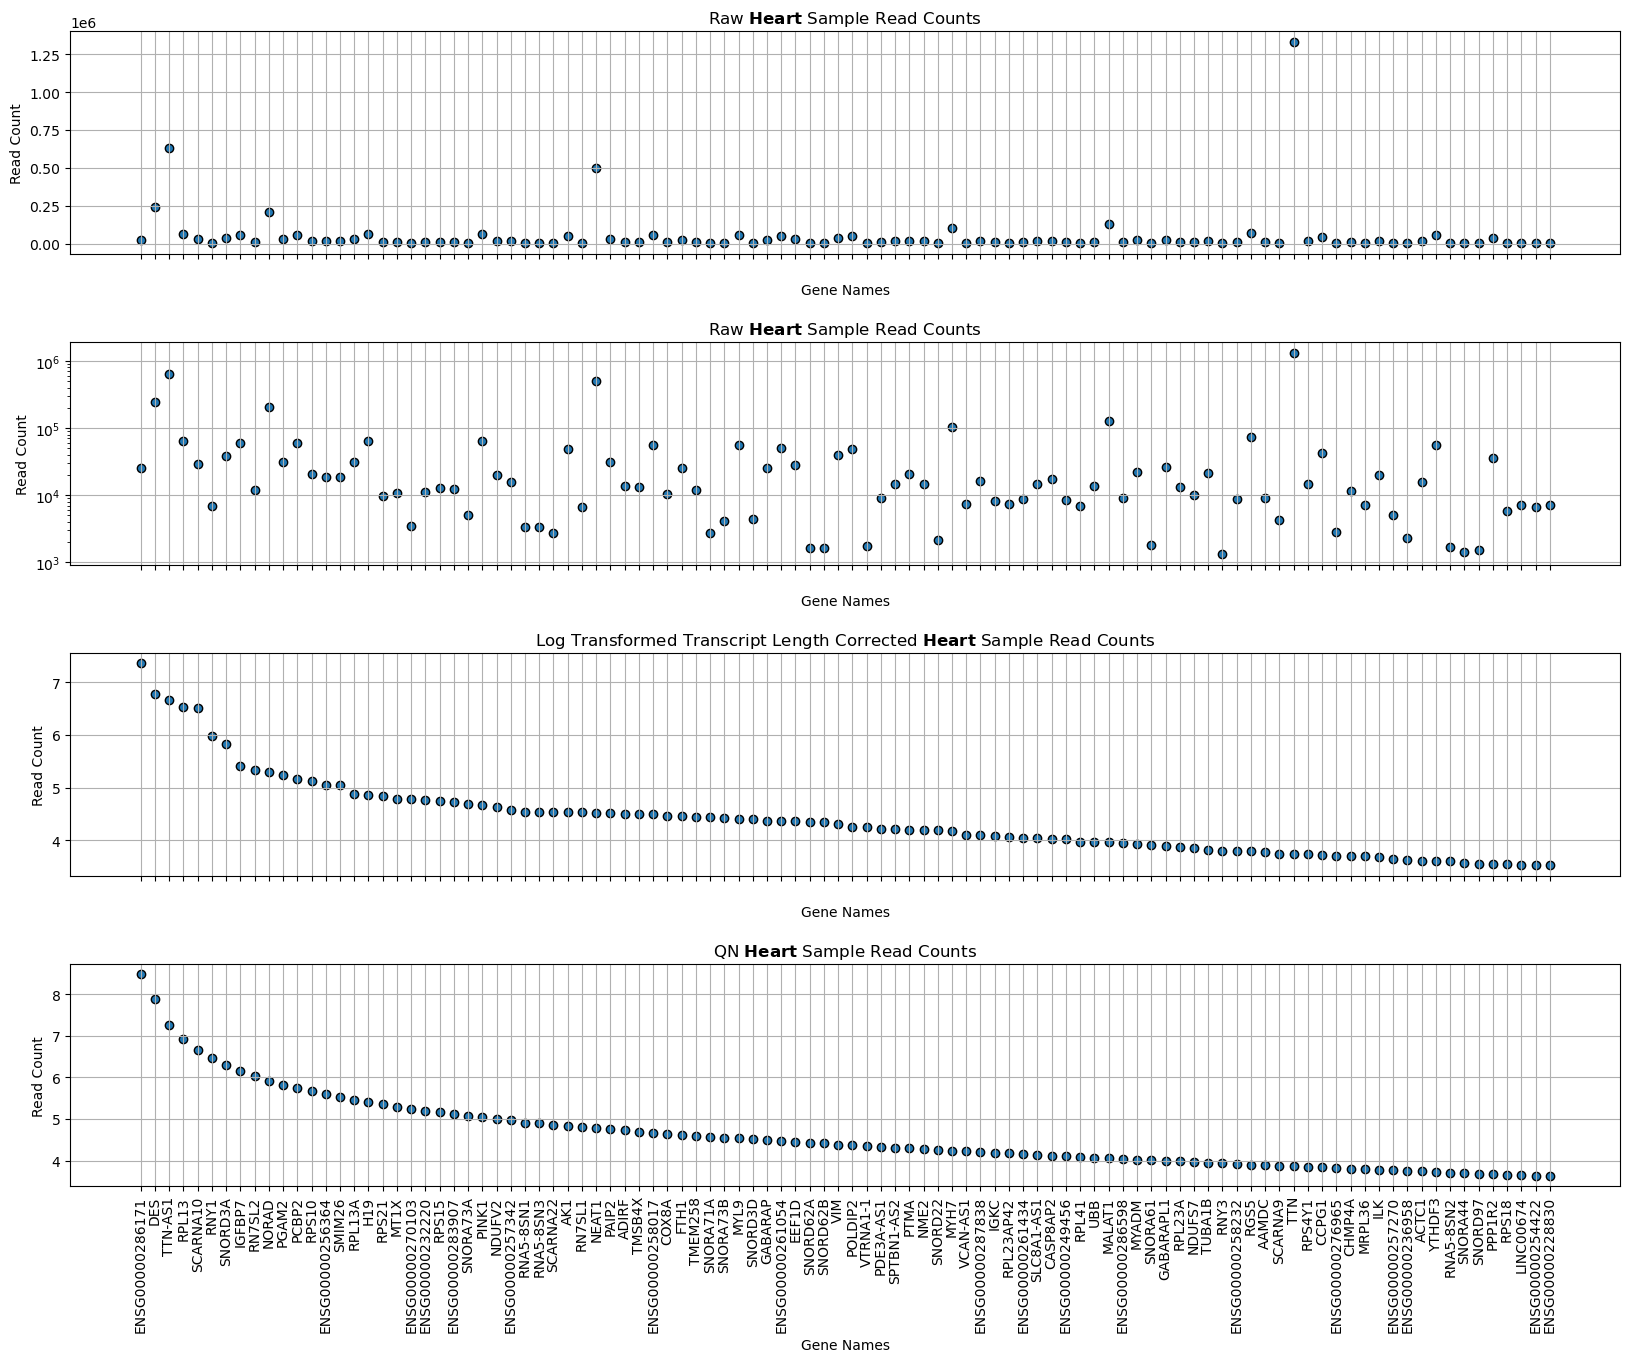

In [30]:
sample_no = 0
sample_name = selected_samples_names[sample_no]

# Transcript Length Corrected Calculations
############################################
T_corrected_matrix = corrected_matrix.T.copy()
log_rc = np.log2(1 + np.array(T_corrected_matrix))

result = [[(index, value, gene_names[index]) for index, value in top_100_indexes(row)] for row in log_rc]
index = [[tup[0] for tup in sublist] for sublist in result]
read_counts = [[tup[1] for tup in sublist] for sublist in result]
names = [[tup[2] for tup in sublist] for sublist in result]

# Transcript Length Corrected Heart Sample Read Counts Plot
plt.subplot(4, 1, 3)
plt.scatter(names[sample_no], read_counts[sample_no], edgecolors='black')
plt.grid()

plt.xlabel('Gene Names')
plt.xticks(color='w')
#plt.xticks([]) 
#plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.title('Log Transformed Transcript Length Corrected ' + ' '.join(['$\\bf{'+i+'}$' for i in sample_name.split(' ')]) +  ' Sample Read Counts')

# Raw Heart Sample Read Counts
##############################
selected_genes_rc = [T_extracted_matrix[sample_no][i] for i in index[sample_no]]

plt.subplot(4, 1, 1)
plt.scatter(names[sample_no], selected_genes_rc, edgecolors='black')
plt.grid()
plt.xlabel('Gene Names')
plt.xticks(color='w')
#plt.xticks([]) 
#plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.title('Raw ' + ' '.join(['$\\bf{'+i+'}$' for i in sample_name.split(' ')]) + ' Sample Read Counts')

# Raw Heart Sample Read Counts + Log-Scaled Y
plt.subplot(4, 1, 2)
plt.scatter(names[sample_no], selected_genes_rc, edgecolors='black')
plt.grid()
plt.xlabel('Gene Names')
plt.xticks(color='w')
#plt.xticks([]) 
#plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.yscale("log")
plt.title('Raw ' + ' '.join(['$\\bf{'+i+'}$' for i in sample_name.split(' ')]) + ' Sample Read Counts')

# QN Calculations 
#################
T_qn_matrix = qn_matrix.T.copy()
selected_genes_rc = [T_qn_matrix[sample_no][i] for i in index[sample_no]]

# QN Heart Sample Read Counts Plot
plt.subplot(4, 1, 4)
plt.scatter(names[sample_no], selected_genes_rc, edgecolors='black')
plt.xlabel('Gene Names')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.title('QN ' + ' '.join(['$\\bf{'+i+'}$' for i in sample_name.split(' ')]) +  ' Sample Read Counts')
plt.grid()


plt.subplots_adjust(hspace=0.4)
plt.show()

# Heart Samples

In [14]:
def top_100_indexes(row):
    sorted_row = sorted(enumerate(row), key=lambda x: x[1], reverse=True)
    return [(index, value) for index, value in sorted_row[:100]]
    
T_extracted_matrix = extracted_matrix.T.copy()
print(T_extracted_matrix.shape)
result = [[(index, value, gene_names[index]) for index, value in top_100_indexes(row)] for row in T_extracted_matrix]

index = [[tup[0] for tup in sublist] for sublist in result]
read_counts = [[tup[1] for tup in sublist] for sublist in result]
names = [[tup[2] for tup in sublist] for sublist in result]

(5, 57447)


In [ ]:
len(selected_genes_rc)

In [ ]:
selected_genes_rc = [T_extracted_matrix[0][i] for i in index[0]]

# Raw Heart Sample Read Counts
plt.scatter(names[0], selected_genes_rc, edgecolors='black')
plt.xlabel('Gene Names')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 10)
    
plt.ylabel('Read Count')
plt.title('Raw Heart Sample Read Counts')
plt.grid()
plt.subplot(2, 3, 1)

# Raw Heart Sample Read Counts + Log-Scaled Y
plt.scatter(names[0], selected_genes_rc, edgecolors='black')
plt.xlabel('Gene Names')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 10)
    
plt.ylabel('Read Count')
plt.yscale("log")
plt.title('Raw Heart Sample Read Counts')
plt.grid()
plt.subplot(2, 3, 2)

In [ ]:
selected_genes_rc = [T_extracted_matrix[0][i] for i in index[0]]

# Raw Heart Sample Read Counts
plt.subplot(4, 1, 1)
plt.scatter(names[0], selected_genes_rc, edgecolors='black')
plt.grid()
plt.xlabel('Gene Names')
plt.xticks(color='w')
#plt.xticks([]) 
#plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.title('Raw $\it{Heart}$ Sample Read Counts')

# Raw Heart Sample Read Counts + Log-Scaled Y
plt.subplot(4, 1, 2)
plt.scatter(names[0], selected_genes_rc, edgecolors='black')
plt.grid()
plt.xlabel('Gene Names')
plt.xticks(color='w')
#plt.xticks([]) 
#plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.yscale("log")
plt.title('Raw Heart Sample Read Counts')

# Transcript Length Corrected Calculations
############################################
T_corrected_matrix = corrected_matrix.T.copy()
log_rc = np.log2(1 + np.array(T_corrected_matrix))

result = [[(index, value, gene_names[index]) for index, value in top_100_indexes(row)] for row in log_rc]
index = [[tup[0] for tup in sublist] for sublist in result]
read_counts = [[tup[1] for tup in sublist] for sublist in result]
names = [[tup[2] for tup in sublist] for sublist in result]

# Transcript Length Corrected Heart Sample Read Counts Plot
plt.subplot(4, 1, 3)
plt.scatter(names[0], read_counts[0], edgecolors='black')
plt.grid()

plt.xlabel('Gene Names')
plt.xticks(color='w')
#plt.xticks([]) 
#plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.title('Log Transformed Transcript Length Corrected Heart Sample Read Counts')

# QN Calculations 
#################
T_qn_matrix = qn_matrix.T.copy()
selected_genes_rc = [T_qn_matrix[0][i] for i in index[0]]

# QN Heart Sample Read Counts Plot
plt.subplot(4, 1, 4)
plt.scatter(names[0], selected_genes_rc, edgecolors='black')
plt.xlabel('Gene Names')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 15)
    
plt.ylabel('Read Count')
plt.title('QN Heart Sample Read Counts')
plt.grid()


plt.subplots_adjust(hspace=0.4)
plt.show()

In [ ]:
T_qn_matrix = qn_matrix.T.copy()
selected_genes_rc = [T_qn_matrix[0][i] for i in index[0]]

# Create the bar plot
plt.scatter(names[0], selected_genes_rc, edgecolors='black')
plt.xlabel('Gene Names')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(20, 10)
    
plt.ylabel('Read Count')
plt.title('QN Heart Sample Read Counts')
plt.grid()
plt.show()